#Final Project 

W210, Spring 2021
Karen Wong, Gunnar Mein, Jia Lu, Thaddeus Segura



# YOLOv5

## Introduction

This notebook will take you through the following steps.
* Basic library imports and the pull request for YOLOv5
* Loading in and merging multiple custom datasets from roboflow.
* Connecting to W&B Tensorboard for visualization.
* Training a custom model.
* Analyzing the results of the model performance.
* Completing custom evaluation.
* Comparing the performance of multiple models simutaneously.
* Extracting results to train a secondary classifier.


## Imports and clone repo

Clone repo, install dependencies and check PyTorch and GPU.

In [ ]:
#Clone Repo
!git clone https://github.com/ultralytics/yolov5  # clone repo
%cd yolov5
%pip install -qr requirements.txt  # install dependencies

import torch
from IPython.display import Image, clear_output  # to display images

clear_output()
print('Setup complete. Using torch %s %s' % (torch.__version__, torch.cuda.get_device_properties(0) if torch.cuda.is_available() else 'CPU'))

In [ ]:
#Basic imports 
import glob
import logging
import math
import os
import random
import shutil
import time
from itertools import repeat
from multiprocessing.pool import ThreadPool
from pathlib import Path
from threading import Thread
import matplotlib.pyplot as plt

import cv2
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image, ExifTags
from torch.utils.data import Dataset
from tqdm import tqdm
from IPython.core.magic import register_line_cell_magic

from utils.general import xyxy2xywh, xywh2xyxy, xywhn2xyxy, clean_str
from utils.torch_utils import torch_distributed_zero_first

# Parameters
help_url = 'https://github.com/ultralytics/yolov5/wiki/Train-Custom-Data'
img_formats = ['bmp', 'jpg', 'jpeg', 'png', 'tif', 'tiff', 'dng']  # acceptable image suffixes
vid_formats = ['mov', 'avi', 'mp4', 'mpg', 'mpeg', 'm4v', 'wmv', 'mkv']  # acceptable video suffixes
logger = logging.getLogger(__name__)

In [ ]:
# mount my drive 
from google.colab import drive
drive.mount('/content/gdrive')

## Load in dataset

Load in Dataset from Roboflow.  Each if block represents a different custom dataset.  This function will load in the requested datasets and merge them.

In [ ]:
def download_data(dataset_list): 
  if 'nyc_base' in dataset_list: #nyc no augmentation
    %mkdir /content/nyc_base
    %cd /content/nyc_base
    !curl -L "https://app.roboflow.com/ds/TZWZCzobl7?key=YOUR_API_KEY" > roboflow.zip; unzip roboflow.zip; rm roboflow.zip

  if 'nyc_aug' in dataset_list: #nyc basic augmentation
    %mkdir /content/nyc_aug
    %cd /content/nyc_aug
    !curl -L "https://app.roboflow.com/ds/M5xg5tj1ys?key=YOUR_API_KEY" > roboflow.zip; unzip roboflow.zip; rm roboflow.zip

  if 'philly_base' in dataset_list: #philly no augmentation
    %mkdir /content/philly_base
    %cd /content/philly_base
    !curl -L "https://app.roboflow.com/ds/RqQao0QTfg?key=YOUR_API_KEY" > roboflow.zip; unzip roboflow.zip; rm roboflow.zip

  if 'nys_base' in dataset_list: #philly no augmentation
    %mkdir /content/nys_base
    %cd /content/nys_base
    !curl -L "https://app.roboflow.com/ds/3VHlkp2ijS?key=YOUR_API_KEY" > roboflow.zip; unzip roboflow.zip; rm roboflow.zip

  if 'philly_aug' in dataset_list: #philly base augmentation
    %mkdir /content/philly_aug
    %cd /content/philly_aug
    !curl -L "https://app.roboflow.com/ds/M5xg5tj1ys?key=YOUR_API_KEY" > roboflow.zip; unzip roboflow.zip; rm roboflow.zip

  if 'p_synth' in dataset_list: #Philly with cooling towers on other cities
    %mkdir /content/p_synth
    %cd /content/p_synth
    !curl -L "https://app.roboflow.com/ds/qPMKoedAoF?key=YOUR_API_KEY" > roboflow.zip; unzip roboflow.zip; rm roboflow.zip

  if 'p_synth_aug' in dataset_list: #Philly with cooling towers on other cities with augmentation
    %mkdir /content/p_synth_aug
    %cd /content/p_synth_aug
    !curl -L "https://app.roboflow.com/ds/vULu0nR2Nv?key=YOUR_API_KEY" > roboflow.zip; unzip roboflow.zip; rm roboflow.zip

  if 'n_fn_synth' in dataset_list: #NYC FN cooling towners on NYC background
    %mkdir /content/n_fn_synth
    %cd /content/n_fn_synth
    !curl -L "https://app.roboflow.com/ds/pHqm3NeZDj?key=YOUR_API_KEY" > roboflow.zip; unzip roboflow.zip; rm roboflow.zip   

  if 'n_fn_synth_aug' in dataset_list: #NYC FN cooling towners on NYC background with augmentation
    %mkdir /content/n_fn_synth_aug
    %cd /content/n_fn_synth_aug
    !curl -L "https://app.roboflow.com/ds/jdTkZh8rRj?key=YOUR_API_KEY" > roboflow.zip; unzip roboflow.zip; rm roboflow.zip

  if 'n_synth_aug' in dataset_list: #NYC single unit cooling towers on NYC back grounds with augmentation.
    %mkdir /content/n_synth_aug
    %cd /content/n_synth_aug
    !curl -L "https://app.roboflow.com/ds/cddEljAnat?key=YOUR_API_KEY" > roboflow.zip; unzip roboflow.zip; rm roboflow.zip

  if 'np_synth_blend' in dataset_list: #NYC and Philly towers with blending effects on other cities.
    %mkdir /content/np_synth_blend
    %cd /content/np_synth_blend
    !curl -L "https://app.roboflow.com/ds/EbkwTojFaQ?key=YOUR_API_KEY" > roboflow.zip; unzip roboflow.zip; rm roboflow.zip   

  if 'vegas_synth_10x' in dataset_list: #vegas manaully extracted towers with snyth augmentation 
    %mkdir /content/vegas_synth_10x
    %cd /content/vegas_synth_10x
    #on other cities
    #!curl -L "https://app.roboflow.com/ds/1oin777Q3Q?key=YOUR_API_KEY" > roboflow.zip; unzip roboflow.zip; rm roboflow.zip
    #on nyc_philly
    !curl -L "https://app.roboflow.com/ds/xuCjV8YkL5?key=YOUR_API_KEY" > roboflow.zip; unzip roboflow.zip; rm roboflow.zip
 
  #make the new base directories
  %mkdir /content/test
  %mkdir /content/test/images
  %mkdir /content/test/labels
  %mkdir /content/train
  %mkdir /content/train/images
  %mkdir /content/train/labels
  %mkdir /content/valid
  %mkdir /content/valid/images
  %mkdir /content/valid/labels
  %cd /content/

  #iterate through the folders and move them all into a master set of files.
  sub_f = ['/train','/valid','/test']
  sub_f2 = ['/images', '/labels']
  for i,ds in enumerate(dataset_list):
    path = '/content/'+ds
    if os.path.isdir(path): #if the folder exists
      for f in sub_f: #train, test, val
        for f2 in sub_f2: #images, labels
          org_path = path+f+f2+'/*'
          dest_path = '/content'+f+f2
          %mv -v $org_path $dest_path
      if i == 0: #for the first folder, copy over the yaml file. 
        yaml = path+'/data.yaml'
        %mv -v $yaml /content/
        %cp -a /content/data.yaml /content/yolov5/

  #map over the data from the extract dataset if its selected.
  if 'EXTRACTED_DATA' in dataset_list:
    extract_path = '/content/gdrive/MyDrive/cooling_towers/extracted_examples/Cities/'
    extracted_cities = os.listdir(extract_path)
    for city in extracted_cities:
      print('IMPORTING CITY:', city)
      new_images = extract_path + city + '/train/images/*'
      new_labels = extract_path + city + '/train/labels/*'
      %cp $new_images /content/train/images
      %cp $new_labels /content/train/labels
  
    

In [ ]:
# # #if you need to remove any datasets.
# %rm -r /content/test
# %rm -r /content/train
# %rm -r /content/valid
# %rm -r /content/nyc_base
# %rm -r /content/philly_base

### Dataset options

Uncomment the desired datasets to load.

* nyc_base - NYC base images
* nyc_aug - NYC with Roboflow augmentations 
* philly_base - Philly base images
* philly_aug - Philly with Roboflow augmentations
* nys_base - New York State with no augmentation 
* p_synth - Philly towers on other cities
* p_synth_aug - Philly towers on otther cities with augmentaition
* n_fn_synth - NYC False negatives on NYC backgrounds
* n_fn_synth_aug - NYC FN's on NYC background with augmentation
* n_synth_aug - NYC single towers on NYC with augmentation
* np_synth_blend - NYC+Philly on new backgrounds with blending.
* vegas_synth_10x - Vegas towers on new backgrounds.
* EXTRACTED_DATA - Towers labeled directly in the tool.

Consistient Validation set = nyc_base + philly_base

In [ ]:
download_data(['nyc_base', 
               'philly_base', 
               'nys_base', 
               #'nyc_aug', 
               #'philly_aug',
               #'p_synth', 
               #'p_synth_aug', 
               #'n_fn_synth', 
               #'n_fn_synth_aug',
               #'n_synth_aug',
               #'np_synth_blend',
               #'vegas_synth_10x',
               #'EXTRACTED_DATA'
               ])


In [ ]:
#to get a count of the training examples. 
print(len(os.listdir('/content/train/images')))
print(len(os.listdir('/content/valid/images')))

#should be 1323 if using NYC + Philly.

In [ ]:
#Manual cell to move everything into validation folder for the secondary classifier extraction.

%mv -v /content/train/images/* /content/valid/images/
%mv -v /content/train/labels/* /content/valid/labels/



### Launch Tensorboard

In [ ]:
# Connect to Tensorboard
%load_ext tensorboard
%tensorboard --logdir runs/train

In [ ]:
# Connect to Weights & Biases
%pip install -q wandb  
!wandb login  # use 'wandb disabled' or 'wandb enabled' to disable or enable

In [ ]:
# Reload tensorboard if it closes. 
%reload_ext tensorboard

 ## Train model

Here are some helpful flags to pass to train.py

    parser.add_argument('--weights', type=str, default='yolov5s.pt', help='initial weights path')
    parser.add_argument('--data', type=str, default='data/coco128.yaml', help='data.yaml path')
    parser.add_argument('--epochs', type=int, default=300)
    parser.add_argument('--batch-size', type=int, default=16, help='total batch size for all GPUs')
    parser.add_argument('--img-size', nargs='+', type=int, default=[640, 640], help='[train, test] image sizes')
    parser.add_argument('--rect', action='store_true', help='rectangular training')
    parser.add_argument('--resume', nargs='?', const=True, default=False, help='resume most recent training')
    parser.add_argument('--nosave', action='store_true', help='only save final checkpoint')
    parser.add_argument('--evolve', action='store_true', help='evolve hyperparameters')
    parser.add_argument('--cache-images', action='store_true', help='cache images for faster training')
    parser.add_argument('--device', default='', help='cuda device, i.e. 0 or 0,1,2,3 or cpu')
    parser.add_argument('--single-cls', action='store_true', help='train multi-class data as single-class')
    parser.add_argument('--log-imgs', type=int, default=16, help='number of images for W&B logging, max 100')
    parser.add_argument('--workers', type=int, default=8, help='maximum number of dataloader workers')
    parser.add_argument('--name', default='exp', help='save to project/name')

The next two cells will create a custom file to train yolov5 XL with the proper number of classes.

If you want to use another size model, you will need to manually change the number of classes to 1 within the model yaml file.

In [ ]:
#customize iPython writefile so we can write variables
@register_line_cell_magic
def writetemplate(line, cell):
    with open(line, 'w') as f:
        f.write(cell.format(**globals()))


In [ ]:
%%writetemplate /content/yolov5/models/custom_yolov5x.yaml

# parameters
nc: 1  # number of classes
depth_multiple: 1.33  # model depth multiple
width_multiple: 1.25  # layer channel multiple

# anchors
anchors:
  - [10,13, 16,30, 33,23]  # P3/8
  - [30,61, 62,45, 59,119]  # P4/16
  - [116,90, 156,198, 373,326]  # P5/32

# YOLOv5 backbone
backbone:
  # [from, number, module, args]
  [[-1, 1, Focus, [64, 3]],  # 0-P1/2
   [-1, 1, Conv, [128, 3, 2]],  # 1-P2/4
   [-1, 3, C3, [128]],
   [-1, 1, Conv, [256, 3, 2]],  # 3-P3/8
   [-1, 9, C3, [256]],
   [-1, 1, Conv, [512, 3, 2]],  # 5-P4/16
   [-1, 9, C3, [512]],
   [-1, 1, Conv, [1024, 3, 2]],  # 7-P5/32
   [-1, 1, SPP, [1024, [5, 9, 13]]],
   [-1, 3, C3, [1024, False]],  # 9
  ]

# YOLOv5 head
head:
  [[-1, 1, Conv, [512, 1, 1]],
   [-1, 1, nn.Upsample, [None, 2, 'nearest']],
   [[-1, 6], 1, Concat, [1]],  # cat backbone P4
   [-1, 3, C3, [512, False]],  # 13

   [-1, 1, Conv, [256, 1, 1]],
   [-1, 1, nn.Upsample, [None, 2, 'nearest']],
   [[-1, 4], 1, Concat, [1]],  # cat backbone P3
   [-1, 3, C3, [256, False]],  # 17 (P3/8-small)

   [-1, 1, Conv, [256, 3, 2]],
   [[-1, 14], 1, Concat, [1]],  # cat head P4
   [-1, 3, C3, [512, False]],  # 20 (P4/16-medium)

   [-1, 1, Conv, [512, 3, 2]],
   [[-1, 10], 1, Concat, [1]],  # cat head P5
   [-1, 3, C3, [1024, False]],  # 23 (P5/32-large)

   [[17, 20, 23], 1, Detect, [nc, anchors]],  # Detect(P3, P4, P5)
  ]


 * If you are not using the XL model, you will need to manually change the number of classes.
 * Recommended Batch sizes: 
 * S = 64, M = 40, L = 24, XL = 16

In [ ]:
#Change into Yolov5 if not in there already. 
%cd /content/yolov5/

In [ ]:
# Train

"""Manually defined batch size.
Auto batch size is below."""

def train_model(model_name, epochs):
  path = model_name + '/weights/'
  new_folder = model_name + "_weights"
  test_labels = 'runs/train/'+model_name+'/test_batch0_labels.jpg'
  test_preds = 'runs/train/'+model_name+'/test_batch0_pred.jpg'
  
  !python train.py \
    --img 640 \
    --batch 10 \
    --epochs $epochs \
    --data '../data.yaml' \
    --weights yolov5x.pt \
    --cache \
    --name $model_name

  %cp -a /content/yolov5/runs/train/$path /content/gdrive/MyDrive/cooling_towers/$new_folder

train_model('nyc.vegasx10.no.blend', 100)



In [ ]:
#This is the same as above but it automatically selects the batch size. 

# def train_model(model_name, model_size, epochs):
#   model_dict = {'small':(yolov5s.pt, 64),
#                 'medium':(yolov5m.pt, 40),
#                 'large':(yolov5l.pt, 24),
#                 'xl':(yolov5x.pt, 16)}

#   path = model_name + '/weights/'
#   new_folder = model_name + "_weights"
#   test_labels = 'runs/train/'+model_name+'/test_batch0_labels.jpg'
#   test_preds = 'runs/train/'+model_name+'/test_batch0_pred.jpg'
  
#   !python train.py \
#     --img 640 \
#     --batch $model_dict[model_size][1] \
#     --epochs $epochs \
#     --data '../data.yaml' \
#     --weights $model_dict[model_size][0]  \
#     --cache \
#     --name $model_name

#   #%cp -a /content/yolov5/runs/train/$path /content/gdrive/MyDrive/cooling_towers/$new_folder

# train_model('xl_2', 'xl', 100)

## Results

There are a number of subcategories within the results analysis section.

* Single Model evaluation using the basic test.py code from yolov5.
* Custom evaluation more inline with stakeholders needs.
* Tuning the optimal inference confidence band for a given model.
* Extracting the FP, FN, and TP's from the validation set.


### Single Model Base evaluation

This is the basic evaluation using the out-of-the-box code from yolov5.

In [ ]:
#Copy the best weights over into the yolov5 folder 
%cp -a /content/gdrive/MyDrive/cooling_towers/comp_weights/nyc_phil_nys_vegx10_rand_weights/best.pt /content/yolov5/
#%cp -a /content/data.yaml /content/yolov5/
%cd yolov5/

In [ ]:
# SINGLE MODEL EVALUATION

!python test.py \
--weights best.pt \
--data data.yaml \
--img-size 640 \
--iou 0.50 \
--conf-thres .001 \
--save-hybrid 


### Custom Results Evaluation

This will implement custom evalution on the models, tune the optimal confidence bands, and extract the results to train a secondary classifier.

#### Helper functions

Helper functions to complete all of the steps listed above.

In [ ]:

def evaluate_run(run_name):
  '''Iterate through the runs of an experiment and evaluate the results.
  Calls evaluate_preds and write_results
  returns tp,fp,fn and creates output files.'''
  tp_total, fp_total, fn_total = 0,0,0
  label_dir = '/content/valid/labels/'
  run_dir = '/content/yolov5/runs/test/'+run_name+'/'
  preds_dir = '/content/yolov5/runs/test/'+run_name+'/labels/'
  label_files = os.listdir(label_dir)
  create_dirs(run_dir) #create the directory.

  #find same named files, make lists of predictions. 
  for file_ in label_files:
    truth = open(label_dir + file_, 'r')
    t_list = [line.strip().split() for line in truth]
    tp, fp = [], []
    pred_file = preds_dir+file_
    if os.path.isfile(pred_file):
      pred = open(preds_dir + file_, 'r')
      p_list = [line.strip().split() for line in pred]
      #iterate through the predictions and score them. 
      tp, fp, tp_truths = evaluate_preds(t_list, p_list)
      tp_total += len(tp)
      fp_total += len(fp)
      for truth in tp_truths:
        t_list.remove(truth)
    fn_total += len(t_list)
    #write the results to the created folders
    write_results(tp, fp, t_list, run_dir, file_)

  return tp_total, fp_total, fn_total


def create_dirs(run_dir):
  output_dir = run_dir + 'results/'
  if not os.path.isdir(output_dir):
    os.makedirs(output_dir) #make the results folder
    #TRUE POSITIVES
    os.makedirs(output_dir+'tp/labels') 
    os.makedirs(output_dir+'tp/images')
    #FALSE POSITIVES
    os.makedirs(output_dir+'fp/labels') 
    os.makedirs(output_dir+'fp/images')
    #FALSE NEGATIVES
    os.makedirs(output_dir+'fn/labels') 
    os.makedirs(output_dir+'fn/images')
  else: 
    print('FOLDER ALREADY EXISTS:', output_dir)


def write_results(tp_list, fp_list, fn_list, output_dir, file_name):
  for l in [tp_list, fp_list, fn_list]:
    if l == tp_list:
      final_dir = output_dir+'results/tp/labels/'+file_name
    elif l == fp_list:
      final_dir = output_dir+'results/fp/labels/'+file_name
    else:
      final_dir = output_dir+'results/fn/labels/'+file_name

    extracted_output = ''
    for example in l:
      for item in example:
        extracted_output += str(item)+' '
      extracted_output += '\n'
    txt_file = open(final_dir, 'w')
    txt_file.write(extracted_output)
    txt_file.close()


def evaluate_preds(test_truth, test_pred):
  '''takes input from evaluate_results.
  generates tp, fp, fn and returns them for each file.'''
  tp_preds, fp_preds, tp_truths = [], [], []
  #calculate the min/max bounding boxes in the prediction. 
  for pred in test_pred:
    tp = False #will track if this is a true positive
    pred_f = list(map(float,pred)) #convert to float
    if len(pred_f) == 5:
      _, pxc, pyc, pw, ph = pred_f #extract data
    else:
      _, pxc, pyc, pw, ph, _ = pred_f
    #calculate mins and maxes.
    px_min = pxc-(pw/2)
    px_max = pxc+(pw/2)
    py_min = pyc-(ph/2)
    py_max = pyc+(ph/2)
    #calculate the min max bounding box areas in truth
    for truth in test_truth: #repeate the approach above.
      truth_f = list(map(float, truth))
      _, txc, tyc, tw, th = truth_f
      tx_min = txc-(tw/2)
      tx_max = txc+(tw/2)
      ty_min = tyc-(th/2)
      ty_max = tyc+(th/2)
      #check for overlap
      #first option is for standard bounding box with intersection.
      overlap = (((tx_min <= px_min <= tx_max or tx_min <= px_max <= tx_max) and
                (ty_min <= py_min <= ty_max or ty_min <= py_max <= ty_max)) or
                #when the pred BB is wider than truth BB
                ((px_min < tx_min and px_max > tx_max) and
                (ty_min <= py_min <= ty_max or ty_min <= py_max <= ty_max)) or
                #when the pred BB is taller than the truth BB 
                ((py_min < ty_min and py_max > ty_max) and
                (tx_min <= px_min <= tx_max or tx_min <= px_max <= tx_max))) 
    
      if overlap:
        tp = True #track that its true, but still keep checking.
        if pred not in tp_preds:
          tp_preds.append(pred) #add to tp list
        if truth not in tp_truths:
          tp_truths.append(truth) #remove from the fn list
    if not tp: #this means the prediction failed them all.
      fp_preds.append(pred)
  return tp_preds, fp_preds, tp_truths


#need to process the lists into relative rates for normalization.
def norm_scores(tp_full, fp_full, fn_full):
  tp_norm, fp_norm, fn_norm = [], [], []
  for i in range(len(tp_full)):
    total = tp_full[i] + fp_full[i] + fn_full[i]
    tp_norm.append(tp_full[i]/total)
    fp_norm.append(fp_full[i]/total)
    fn_norm.append(fn_full[i]/total)
  return tp_norm, fp_norm, fn_norm


def calc_f1(tp_full, fp_full, fn_full):
  f1 = []
  for i in range(len(tp_full)):
    if tp_full[i] > 0 and fp_full[i] > 0 and fn_full[i] > 0:
      p = (tp_full[i]/(tp_full[i]+fp_full[i]))
      r = (tp_full[i]/(tp_full[i]+fn_full[i]))
      f1.append((2*(p*r))/(p+r))
    else:
      f1.append(0)
  return f1


#plot
def plot_rates(tp,fp,fn,f1,confs):
  fig, axs = plt.subplots(2, 2, sharex=True,sharey=True)
  axs[0, 0].plot(confs, tp)
  axs[0, 0].set_title('True Positive Rate')
  axs[0, 1].plot(confs, fp, 'tab:orange')
  axs[0, 1].set_title('False Positive Rate')
  axs[1, 0].plot(confs, fn, 'tab:green')
  axs[1, 0].set_title('False Negative Rate')
  axs[1, 1].plot(confs, f1, 'tab:red')
  axs[1, 1].set_title('F1')

  fig.set_figheight(10)
  fig.set_figwidth(10)
  for ax in axs.flat:
      ax.set(xlabel='Confidence Threshold', ylabel='Rates')

  # Hide x labels and tick labels for top plots and y ticks for right plots.
  for ax in axs.flat:
      ax.label_outer()

def img2label_paths(img_paths):
    # Define label paths as a function of image paths
    sa, sb = os.sep + 'images' + os.sep, os.sep + 'labels' + os.sep  # /images/, /labels/ substrings
    return [x.replace(sa, sb, 1).replace('.' + x.split('.')[-1], '.txt') for x in img_paths]

def extract_boxes3(image_path, run_path, upper_conf=1.0):
  """Run this manually after an evaluation run to extract images for a secondary classifier.
  Image_path = the path where the validation images are.
  run_path = the path where the 'results' folder is
  upper_conf = the upper confidence band of images to ignore.
  Outputs: images into the images folders that were created from the run evaluation. """
  path = Path(image_path)  # images dir
  shutil.rmtree(path / 'classifier') if (path / 'classifier').is_dir() else None  # remove existing
  files = list(path.rglob('*.*'))
  n = len(files)  # number of files
  for im_file in tqdm(files, total=n):
      if im_file.suffix[1:] in img_formats:
          # image
          im = cv2.imread(str(im_file))[..., ::-1]  # BGR to RGB
          h, w = im.shape[:2]

          # labels
          for result_type in ['fn','fp','tp']:

            #lb_file = str(Path(img2label_paths([str(im_file)])[0]))
            lb_file = im_file.stem
            lb_file = run_path+'/'+result_type+'/labels/'+lb_file+'.txt'

            if Path(lb_file).exists():
                with open(lb_file, 'r') as f:
                    lb = np.array([x.split() for x in f.read().strip().splitlines()], dtype=np.float32)  # labels

                for j, x in enumerate(lb):
                  extract = True
                  if len(x) == 6: #if this contains a confidence interval 
                    if x[-1] > upper_conf: #default of 1.
                      extract = False #skip this example if its higher than the upper bound
                    else: #otherwise remove the label and continue. 
                      x = x[:-1]

                  if extract:
                    c = int(x[0])  # class
                    #f = (run_path+'/'+result_type+'/images') / f'{c}' / f'{path.stem}_{im_file.stem}_{j}.jpg'  # new filename
                    f = run_path+'/'+result_type+'/images/'+im_file.stem+'.jpg'
                    # if not f.parent.is_dir():
                    #     f.parent.mkdir(parents=True)

                    b = x[1:] * [w, h, w, h]  # box
                    b[2:] = b[2:].max()  # rectangle to square
                    b[2:] = b[2:] * 1.5 + 25  # pad
                    b = xywh2xyxy(b.reshape(-1, 4)).ravel().astype(np.int)

                    b[[0, 2]] = np.clip(b[[0, 2]], 0, w)  # clip boxes outside of image
                    b[[1, 3]] = np.clip(b[[1, 3]], 0, h)
                    assert cv2.imwrite(str(f), im[b[1]:b[3], b[0]:b[2]]), f'box failure in {f}'

#### Extract Secondary Classifer Images

This will complete custom evaluation and then you can extract the results from here for secondary training.

In [ ]:
#download best weights 
%cp -a /content/gdrive/MyDrive/cooling_towers/comp_weights/nyc_phil_nys_vegx10_rand_weights/best.pt /content/yolov5/
%cd yolov5/

In [ ]:
!python test.py \
--weights best.pt \
--data data.yaml \
--img-size 640 \
--iou 0.50 \
--conf-thres .25 \
--save-txt \
--save-conf \
--name extract_run7

In [ ]:
#Evaluate a single run 
tp, fp, fn = evaluate_run('extract_run7')
print('TRUE POSITIVES', tp, 
      '\nFALSE POSITIVES', fp,
      '\nFALSE NEGATIVES', fn)

In [ ]:
#extract the different categories as images for a single run.
extract_boxes3('/content/valid', '/content/yolov5/runs/test/extract_run6/results', .65)

In [ ]:
#copy over the extracted results. 
%mkdir /content/gdrive/MyDrive/cooling_towers/classifier_0.25-0.65/
%cp -a /content/yolov5/runs/test/extract_run6/results /content/gdrive/MyDrive/cooling_towers/classifier_0.25-0.65/results 

In [ ]:
test = os.listdir('/content/yolov5/runs/test/extract_run6/results/fp/images')
len(test)

319

#### Inference Fine Tuning

This is used to tune the confidence threshold used for inference.

In [ ]:
#copy over the best.pt file you want to work with.
%cp -a /content/gdrive/MyDrive/cooling_towers/comp_weights/NYC_base_weights/best.pt /content/yolov5/

In [ ]:
def evaluate_test(run_name, conf):
  !python test.py \
    --weights best.pt \
    --data data.yaml \
    --img-size 640 \
    --iou 0.5 \
    --conf-thres $conf \
    --save-txt \
    --name $run_name

  tp, fp, fn = evaluate_run(run_name)
  print('TRUE POSITIVES', tp, 
      '\nFALSE POSITIVES', fp,
      '\nFALSE NEGATIVES', fn)
  return tp, fp, fn

In [ ]:
%cd /content/yolov5/

In [ ]:
confs = np.arange(0.01,1,0.01)
names = ['1run_'+str(c.round(2)) for c in confs]

tp_full, fp_full, fn_full = [], [], []
for i in range(len(names)):
  tp,fp,fn = evaluate_test(names[i], confs[i].round(2))
  tp_full.append(tp)
  fp_full.append(fp)
  fn_full.append(fn)

In [ ]:
for i in range(len(tp_full)):
  print(tp_full[i], fp_full[i], fn_full[i])

In [ ]:
tp_norm = [float(i)/max(tp_full) for i in tp_full]
fp_norm = [float(i)/max(fp_full) for i in fp_full]

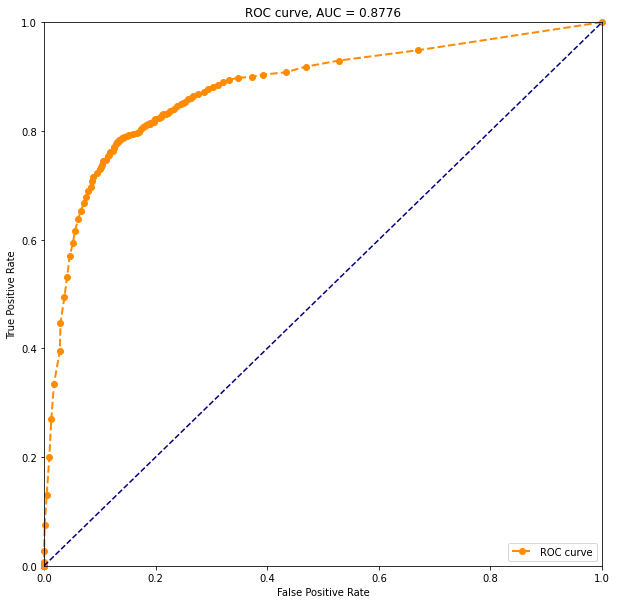

In [ ]:
auc = -1 * np.trapz(tp_norm, fp_norm)

plt.rcParams["figure.figsize"] = (10,10)
plt.plot(fp_norm, tp_norm, linestyle='--', marker='o', color='darkorange', lw = 2, label='ROC curve', clip_on=False)
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curve, AUC = %.4f'%auc)
plt.legend(loc="lower right")
plt.savefig('AUC_example.png')

# plt.show()

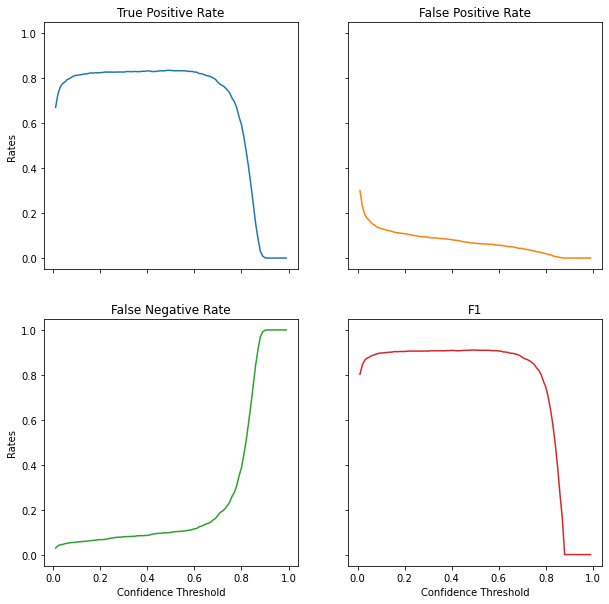

In [ ]:
#normalize
tp,fp,fn = norm_scores(tp_full, fp_full, fn_full)

#calculate F1
f1 = calc_f1(tp_full, fp_full, fn_full)
f1_a = np.asarray(f1)
print('BEST CONFIDENCE THRESHOLD: {:.2%}'.format(confs[f1_a.argmax()]))

#plot
plot_rates(tp,fp,fn,f1,confs)

#### Multiple models evaluation

In [ ]:
#if you aren't already in the folder
%cd /content/yolov5/

In [ ]:
#if you are rerunning, delete the old folders to avoid naming issues.
%rm -r /content/yolov5/runs/test

In [ ]:
#Helper functions

def get_multiple(master_path):
  weights = os.listdir('/content/gdrive/MyDrive/cooling_towers/comp_weights/')
  for w in weights:
    name = w.split('_weights')[0]
    new_path = '/content/gdrive/MyDrive/cooling_towers/comp_weights/'+ w + '/best.pt'
    evaluate_single(name, new_path)

def evaluate_single(run_name, weights_path):
  !python test.py \
    --weights $weights_path \
    --data data.yaml \
    --img-size 640 \
    --iou 0.5 \
    --conf-thres .25 \
    --save-txt \
    --save-conf \
    --name $run_name

  tp, fp, fn = evaluate_run(run_name)
  print('\n############ RUN NAME :', run_name, "############",
      '\nTRUE POSITIVES', tp, 
      '\nFALSE POSITIVES', fp,
      '\nFALSE NEGATIVES', fn)
  return tp, fp, fn


In [ ]:
tp, fp, fn = evaluate_run('single2')
print('\n############ RUN NAME :', 'single2', "############",
    '\nTRUE POSITIVES', tp, 
    '\nFALSE POSITIVES', fp,
    '\nFALSE NEGATIVES', fn)

In [ ]:
#evaluate single model
evaluate_single('test1', '/content/gdrive/MyDrive/cooling_towers/comp_weights/nyc_phil_nys_vegx10_rand_weights/best.pt')

(8403, 923, 165)

In [ ]:
#pass in the master path where all trained models are stored.

master_path = '/content/gdrive/MyDrive/cooling_towers/comp_weights/'
get_multiple(master_path)

#### Confidence Distrobution analysis.

Understand the confidence of TP's and FP's to understand where to connect the secondary classifier.

In [ ]:
#### HELPER FUNCTIONS ####

#get the confidence's into lists by class.
def get_confs(run_name):
  base_path = '/content/yolov5/runs/test/' + run_name + '/results/'
  tp_confs = extract_conf(base_path, 'tp')
  fp_confs = extract_conf(base_path, 'fp')
  return tp_confs, fp_confs

def extract_conf(base_path, category):
  """Called by get_confs, takes a path and returns a list of confidences."""
  results = []
  full_path = base_path + category +'/labels/'
  for f in os.listdir(full_path):
    pred = open(full_path+f, 'r')
    p_list = [line.strip().split() for line in pred]
    print
    if p_list:
      for p in p_list:
        p_f = list(map(float,p)) #convert to float
        results.append(p_f[-1])
  return results



In [ ]:
tp_test, fp_test = get_confs('8')

Text(0.5, 1.0, 'False Positive Rate')

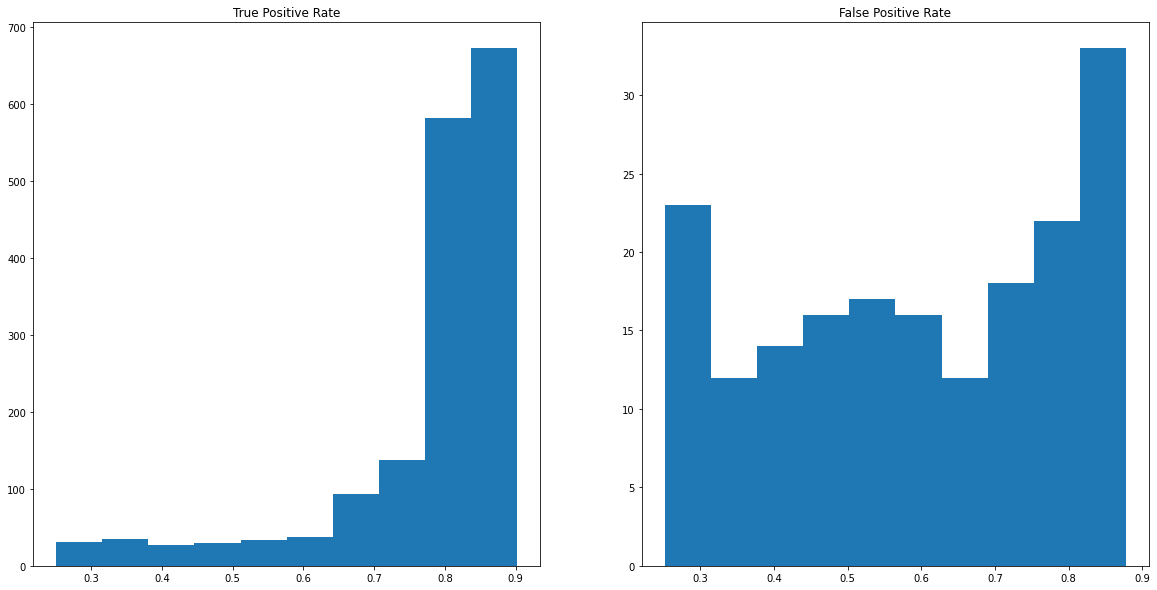

In [ ]:
fig, axs = plt.subplots(1,2, sharey = False, figsize=(20,10))

axs[0].hist(tp_test, bins=10)
axs[1].hist(fp_test, bins=10)
axs[0].set_title('True Positive Rate')
axs[1].set_title('False Positive Rate')

In [ ]:
tp_count = sum([i<0.65 for i in tp_test])
print(tp_count)
print('% of TPs with less than 65% conf', sum([i<0.65 for i in tp_test])/len(tp_test))

fp_count = sum([i<0.65 for i in fp_test])
print(fp_count)
print('% of FPs with less than 65% conf', sum([i<0.65 for i in fp_test])/len(fp_test))

#### Extract Classification Dataset

This will extract the TP's from the predictions

In [ ]:
def img2label_paths(img_paths):
    # Define label paths as a function of image paths
    sa, sb = os.sep + 'images' + os.sep, os.sep + 'labels' + os.sep  # /images/, /labels/ substrings
    return [x.replace(sa, sb, 1).replace('.' + x.split('.')[-1], '.txt') for x in img_paths]

def extract_boxes(path):
  path = Path(path)  # images dir
  shutil.rmtree(path / 'classifier') if (path / 'classifier').is_dir() else None  # remove existing
  files = list(path.rglob('*.*'))
  n = len(files)  # number of files
  for im_file in tqdm(files, total=n):
      if im_file.suffix[1:] in img_formats:
          # image
          im = cv2.imread(str(im_file))[..., ::-1]  # BGR to RGB
          h, w = im.shape[:2]

          # labels
          lb_file = Path(img2label_paths([str(im_file)])[0])
          print('LABEL FILE NAME', lb_file)
          if Path(lb_file).exists():
              with open(lb_file, 'r') as f:
                  lb = np.array([x.split() for x in f.read().strip().splitlines()], dtype=np.float32)  # labels

              for j, x in enumerate(lb):
                  c = int(x[0])  # class
                  f = (path / 'classifier') / f'{c}' / f'{path.stem}_{im_file.stem}_{j}.jpg'  # new filename
                  if not f.parent.is_dir():
                      f.parent.mkdir(parents=True)

                  b = x[1:] * [w, h, w, h]  # box
                  # b[2:] = b[2:].max()  # rectangle to square
                  b[2:] = b[2:] * 1.5 + 5  # pad
                  b = xywh2xyxy(b.reshape(-1, 4)).ravel().astype(np.int)

                  b[[0, 2]] = np.clip(b[[0, 2]], 0, w)  # clip boxes outside of image
                  b[[1, 3]] = np.clip(b[[1, 3]], 0, h)
                  assert cv2.imwrite(str(f), im[b[1]:b[3], b[0]:b[2]]), f'box failure in {f}'

In [ ]:
test = '/content/train/labels/1000002354_png.rf.ab89f1cc37e6020fd99be238b1f2225e.txt'
test = test.split('/labels/')[1]
print(test)

In [ ]:
extract_boxes('/content/train')

In [ ]:
#copy the generated files over. 
%cp -a /content/train/classifier/training_positives /content/gdrive/MyDrive/cooling_towers/run_feb_10/